# Check TRENDY LAI

In [22]:
import xarray as xr
import matplotlib.pyplot as plt

import etunc.config as cfg
import etunc.grid as rg
import etunc.units as units
import etunc.binning as binning
import etunc.temporal as temporal
import etunc.load.trendy as lt

In [14]:
EXPERIMENT = "S3"  # "S2": climate + CO2; "S3": climate + CO2 + land use change
FAMILY = f"trendy_{EXPERIMENT.lower()}"

TIME_SLICE = cfg.TIME_SLICE
TARGET_RES = cfg.TARGET_RES

VARIABLES = ["evapotrans", "lai"]

In [30]:
models =  lt.models()

ann = {}
clim = {}
per_model = []
for model in models:
    print(f"\n=== {model} ===")
    # 1. Monthly native fields over TIME_SLICE. A model whose files are inconsistent is skipped
    try:
        raw = lt.load_native(model, EXPERIMENT, TIME_SLICE, VARIABLES)
    except ValueError as err:
        print(f"{model}: {err}, skipping")
        continue
    src_grid = rg.bounded_src_grid(raw["evapotrans"])

    # 3. ET in W/m2 (P is the forcing's and Rn ERA5's, above)
    monthly = {
        "et": units.convert_units("et", raw["evapotrans"]),  # kg m-2 s-1 x L
        "lai": raw["lai"].assign_attrs(units="m2/m2"),
    }

    # 4. Annual means over complete years: ET needs all 12 months, a missing LAI month counts as 0
    ann[model] = {
        k: temporal.aggregate(da, "year", require_all_months=(k != "lai"), label=f"{model}/{k}")
        for k, da in monthly.items()
    }

    # 5. Native land mask: Natural Earth land, without Greenland/Iceland
    land = rg.landne_mask(src_grid)
    ann[model] = {k: rg.mask_to_land(da, land, f"{model}/{k}") for k, da in ann[model].items()}

    # LAI missing on land (cells outside the model's own land mask, unvegetated cells) is set to 0;
    # masking again after the fill sets the ocean back to NaN
    n_nan = int(ann[model]["lai"].isnull().sum())
    ann[model]["lai"] = rg.mask_to_land(ann[model]["lai"].fillna(0), land, f"{model}/lai")
    print(f"{model}/lai: {n_nan - int(ann[model]['lai'].isnull().sum())} land gridcell-years with missing LAI set to 0")

    # 6. ET outlier filter (on land, before regridding, so an outlier does not enter its target cell)
    ann[model]["et"] = binning.drop_et_outliers(ann[model]["et"], cfg.MIN_ANNUAL_ET, label=f"{model}/et")

    # 7. Conservative regridding onto the target grid (NaN where more than NA_THRESH is missing)
    regridder = rg.bounded_conservative_regridder(src_grid, TARGET_RES)
    ann[model] = {
        k: rg.on_grid(rg.regrid_with_na_thresh(da, regridder, cfg.NA_THRESH), TARGET_RES, f"{model}/{k}")
        for k, da in ann[model].items()
    }

    # 8. Domain without Antarctica
    ann[model] = {k: da.sel(lat=cfg.LAT_BNDS) for k, da in ann[model].items()}

    # 10. Climatological LAI, P and Rn over those years
    clim[model] = {k: temporal.aggregate(ann[model][k], "clim", label=f"{model}/{k}") for k in ("lai",)}

    data = {"et": ann[model]["et"], **clim[model]}

    # The model is the source of its one member
    per_model.append(xr.Dataset(data).expand_dims(member=[model]).assign_coords(source=("member", [model])))

if not per_model:
    raise RuntimeError("No model could be loaded.")
inputs = xr.concat(per_model, dim="member", join="outer", combine_attrs="drop_conflicts")


=== CABLE-POP ===
CABLE-POP/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
CABLE-POP/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
CABLE-POP/lai: 91406 land gridcell-years with missing LAI set to 0
CABLE-POP/et: 206 gridcell-years with annual ET < -2.0 W/m2 set to NaN (206 within LAT_BNDS; min -5.56)
CABLE-POP/lai: climatology of 14 years; 0 gridcells have missing years

=== CARDAMOM ===


/glade/u/home/bbuchovecky/projects/et_unc/etunc/load/trendy.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 120. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, decode_times=False, chunks={"time": 120})
/glade/u/home/bbuchovecky/projects/et_unc/etunc/load/trendy.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 120. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, decode_times=False, chunks={"time": 120})


CARDAMOM/et: annual means of 12 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
CARDAMOM/lai: annual means of 12 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
CARDAMOM/lai: 345024 land gridcell-years with missing LAI set to 0
CARDAMOM/et: 31 gridcell-years with annual ET < -2.0 W/m2 set to NaN (31 within LAT_BNDS; min -10.1)
CARDAMOM/lai: climatology of 12 years; 0 gridcells have missing years

=== CLASSIC ===
CLASSIC/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
CLASSIC/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
CLASSIC/lai: 86842 land gridcell-years with missing LAI set to 0
CLASSIC/et: 1 gridcell-years with annual ET < -2.0 W/m2 set to NaN (1 within LAT_BNDS; min -2.04)
CLASSIC/lai: climatology of 14 years; 0 gridcells have missing years

=== CLM ===
CLM/et: annual means of 14

/glade/u/home/bbuchovecky/projects/et_unc/etunc/load/trendy.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 120. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, decode_times=False, chunks={"time": 120})
/glade/u/home/bbuchovecky/projects/et_unc/etunc/load/trendy.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 120. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, decode_times=False, chunks={"time": 120})


ELM-FATES/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
ELM-FATES/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
ELM-FATES/lai: 42 land gridcell-years with missing LAI set to 0
ELM-FATES/et: 180 gridcell-years with annual ET < -2.0 W/m2 set to NaN (180 within LAT_BNDS; min -6.93)
ELM-FATES/lai: climatology of 14 years; 0 gridcells have missing years

=== IBIS ===


...

IBIS/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
IBIS/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
IBIS/lai: 363622 land gridcell-years with missing LAI set to 0
IBIS/et: 0 gridcell-years with annual ET < -2.0 W/m2 set to NaN
IBIS/lai: climatology of 14 years; 0 gridcells have missing years

=== iMAPLE ===
iMAPLE/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
iMAPLE/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
iMAPLE/lai: 0 land gridcell-years with missing LAI set to 0
iMAPLE/et: 574 gridcell-years with annual ET < -2.0 W/m2 set to NaN (574 within LAT_BNDS; min -10.6)
iMAPLE/lai: climatology of 14 years; 0 gridcells have missing years

=== ISAM ===


/glade/u/home/bbuchovecky/projects/et_unc/etunc/load/trendy.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 120. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, decode_times=False, chunks={"time": 120})


ISAM: ISAM/S3: no lai file, skipping

=== JSBACH ===
JSBACH/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
JSBACH/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
JSBACH/lai: 25872 land gridcell-years with missing LAI set to 0
JSBACH/et: 42 gridcell-years with annual ET < -2.0 W/m2 set to NaN (42 within LAT_BNDS; min -5.61)
JSBACH/lai: climatology of 14 years; 0 gridcells have missing years

=== JULES-ES ===
JULES-ES/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
JULES-ES/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
JULES-ES/lai: 357434 land gridcell-years with missing LAI set to 0
JULES-ES/et: 209 gridcell-years with annual ET < -2.0 W/m2 set to NaN (209 within LAT_BNDS; min -10.3)
JULES-ES/lai: climatology of 14 years; 0 gridcells have 

/glade/u/home/bbuchovecky/projects/et_unc/etunc/load/trendy.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 120. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, decode_times=False, chunks={"time": 120})
/glade/u/home/bbuchovecky/projects/et_unc/etunc/load/trendy.py:165: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 120. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, decode_times=False, chunks={"time": 120})


LPJwsl/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
LPJwsl/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
LPJwsl/lai: 344862 land gridcell-years with missing LAI set to 0
LPJwsl/et: 0 gridcell-years with annual ET < -2.0 W/m2 set to NaN
LPJwsl/lai: climatology of 14 years; 0 gridcells have missing years

=== LPX-Bern ===
LPX-Bern/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
LPX-Bern/lai: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, missing months counted as 0
LPX-Bern/lai: 341894 land gridcell-years with missing LAI set to 0
LPX-Bern/et: 0 gridcell-years with annual ET < -2.0 W/m2 set to NaN
LPX-Bern/lai: climatology of 14 years; 0 gridcells have missing years

=== ORCHIDEE ===
ORCHIDEE/et: annual means of 14 complete years; 0 gridcell-years with partial (1-11) val

In [37]:
area = rg.land_area(rg.target_grid(TARGET_RES)).sel(lat=cfg.LAT_BNDS)


def land_mean(ann: xr.DataArray, area: xr.DataArray) -> xr.DataArray:
    """Land-area weighted mean over the valid cells of each year."""
    w = area.where(ann.notnull(), 0)
    return (ann.fillna(0) * w).sum(["lat", "lon"]) / w.sum(["lat", "lon"])

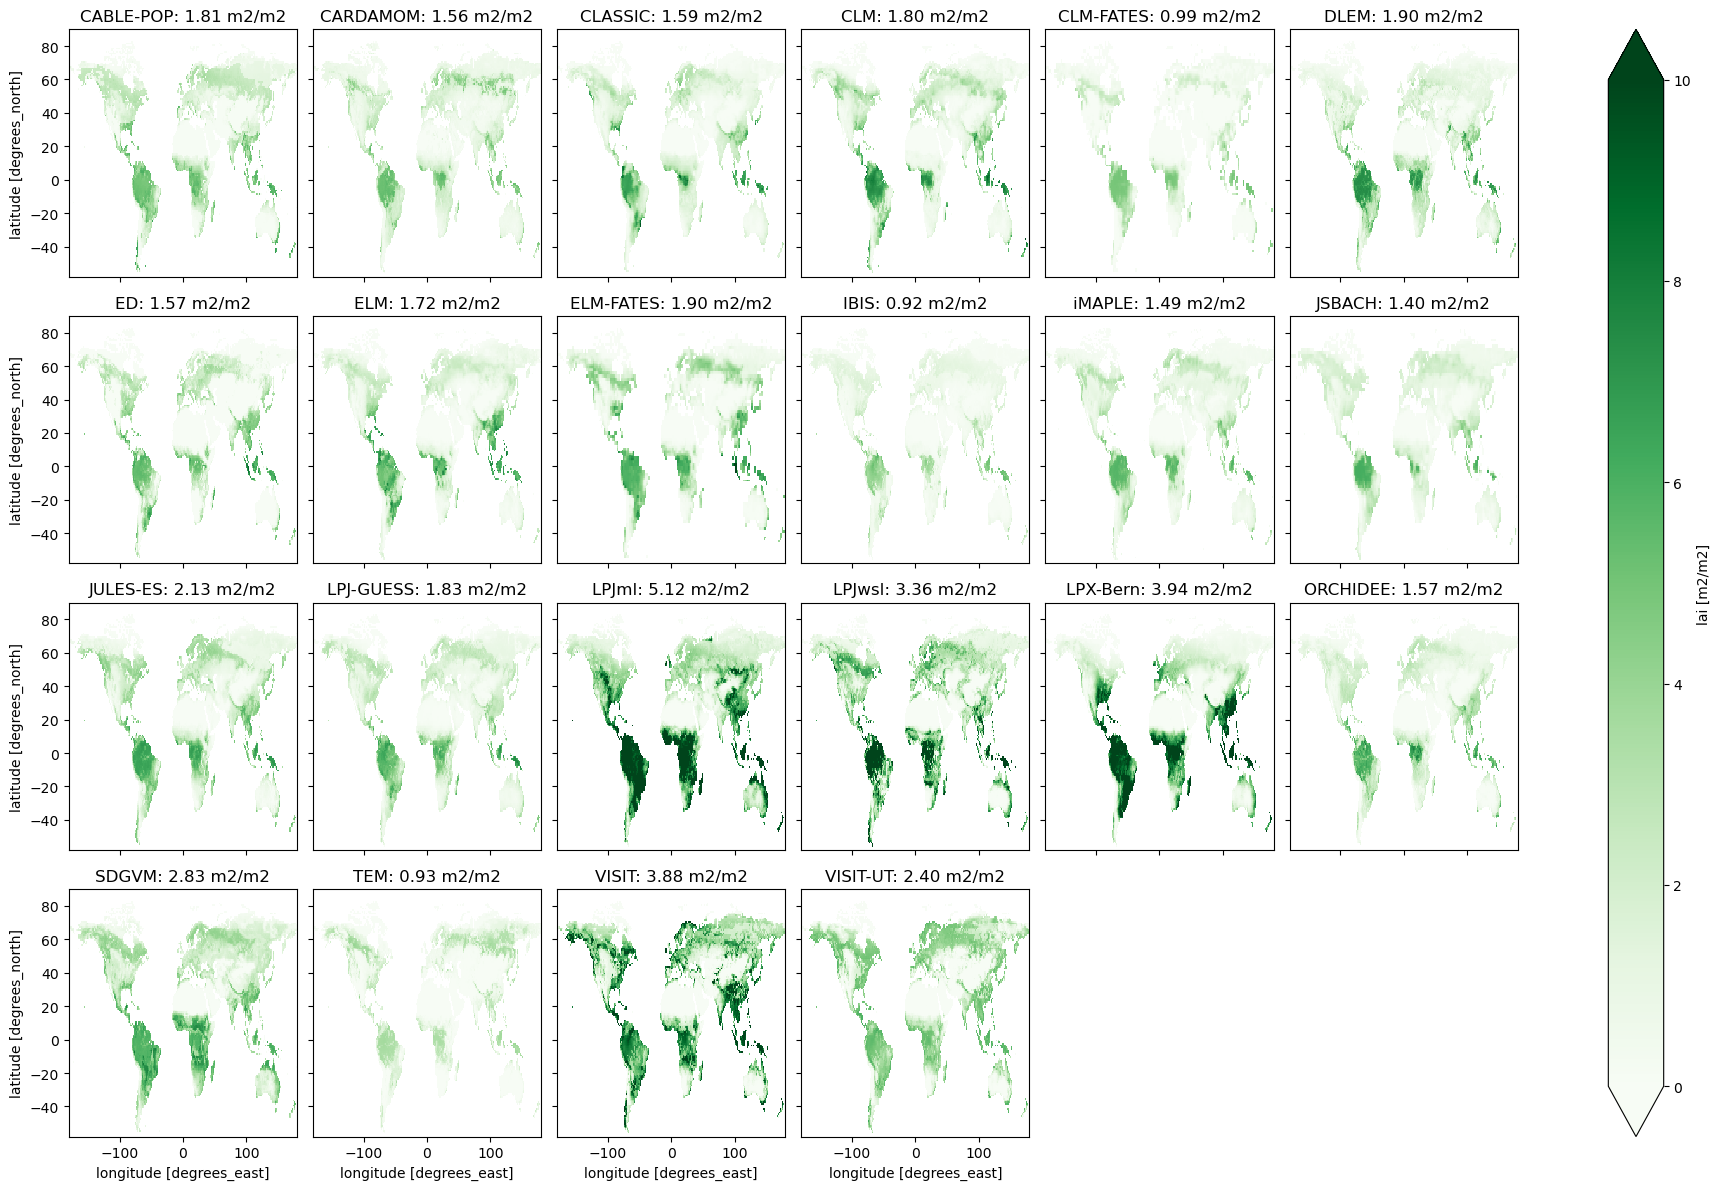

In [43]:
fg = inputs.lai.plot(col="member", col_wrap=6, vmin=0, vmax=10, cmap="Greens")
for ax, m in zip(fg.axs.ravel(), inputs.member):
    lm = land_mean(inputs.lai.sel(member=m), area)
    ax.set_title(f"{m.item()}: {lm:0.2f} m2/m2")